# Quantum Random Number Generator
### Heha Code Crafters · AstraCode Qiskit Fall Fest 2026 · Project 4

**Our question:** can you tell numbers from a quantum computer apart from ordinary computer numbers just by looking at them?

# Table of Contents

* [Before you begin](#before)
* [1. The idea: superposition and measurement](#idea)
* [2. Build, run and analyse the generator](#qrng)
    - [2.1 Step 1: Map the problem to a quantum circuit](#step1)
    - [2.2 Step 2: Optimize for hardware](#optimize)
    - [2.3 Step 3: Execute on hardware and simulator](#execute)
    - [2.4 Step 4: Post-process and analyse the results](#post)
    - [2.5 Noise Detective](#noise)
* [3. The three questions](#questions)
* [Conclusions](#conclusions)

## Before you begin <a id="before"></a>

This notebook compares random bits from a real IBM quantum computer, a noisy simulator and Python's `random` module. You do **not** need an IBM account: the hardware and simulator bits were collected earlier and are saved in the `data/` folder.

To run it, open it from the `qrng` folder and choose *Kernel → Restart & Run All*. You need `matplotlib` and `notebook`. The cells that draw and run the circuit with Qiskit are optional: if Qiskit isn't installed, they print a message and the notebook carries on.

<div class="alert alert-block alert-info">

**Note:** never paste an IBM API token into this notebook. Credentials are only needed to collect new hardware data, which we have already done.

</div>

## Imports and data
Load the three sets of 1,000 bits and check that they only contain 0s and 1s.

In [1]:

DATASET = "saved"

import json, math, random
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from statistical_comparison import generate_python_random_bits

DATA = Path("data")
N_QUBITS = 8


def load_dataset(path):
    """Read a JSON dataset file containing metadata and bits."""
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def load_bits(path):
    """Read the list of 0/1 bits from one of Person 1's JSON datasets."""
    return load_dataset(path)["bits"]


def bits_to_numbers(bits, n_qubits=N_QUBITS):
    """Group bits into n_qubits-sized chunks and read each as a binary number."""
    return [
        int("".join(map(str, bits[i:i + n_qubits])), 2)
        for i in range(0, len(bits) - n_qubits + 1, n_qubits)
    ]


SAVED_PATH = DATA / "quantum_bits_hardware.json"
LIVE_PATH = DATA / "live_runs" / "latest.json"

if DATASET == "live":
    if LIVE_PATH.exists():
        hw_path = LIVE_PATH
        mode_label = "LIVE"
    else:
        print(f"Warning: Live dataset '{LIVE_PATH}' not found. Falling back to saved baseline.")
        hw_path = SAVED_PATH
        mode_label = "saved"
else:
    hw_path = SAVED_PATH
    mode_label = "saved"

hw_dataset = load_dataset(hw_path)
hardware = hw_dataset["bits"]
hw_source = hw_dataset.get("source", "unknown")
hw_job_id = hw_dataset.get("job_id", "unknown")

if mode_label == "LIVE":
    print(f"Showing LIVE data from {hw_source}, job {hw_job_id}")
else:
    print(f"Showing saved data from {hw_source}, job {hw_job_id}")

noisy_dataset = load_dataset(DATA / "quantum_bits_noisy.json")
noisy = noisy_dataset["bits"]

# Unified Python baseline from statistical_comparison 
python_bits = generate_python_random_bits(len(hardware), seed=42)

datasets = {
    f"IBM hardware\n({hw_source})": hardware,
    "Noisy simulator\n(simulation, not\nmeasured quantum data)": noisy,
    "Python\nrandom": python_bits,
}
COLORS = ["#4f46e5", "#f59e0b", "#10b981"]
print({name.replace("\n", " "): len(bits) for name, bits in datasets.items()})


Showing saved data from ibm_marrakesh, job dbplvroqtr0c738elbe0
{'IBM hardware (ibm_marrakesh)': 1000, 'Noisy simulator (simulation, not measured quantum data)': 1000, 'Python random': 1000}


In [2]:
# Quick check that every dataset only contains 0s and 1s, and how many bits it has.
for name, bits in datasets.items():
    label = name.replace("\n", " ")
    assert set(bits) <= {0, 1}, f"{label} contains values other than 0 and 1"
    print(f"{label:<48} {len(bits)} bits, {sum(bits)} ones")


IBM hardware (ibm_marrakesh)                     1000 bits, 512 ones
Noisy simulator (simulation, not measured quantum data) 1000 bits, 464 ones
Python random                                    1000 bits, 514 ones


# 1. The idea: superposition and measurement <a id="idea"></a>

## The quantum idea in plain language

A normal computer bit is always 0 or 1. A **qubit** can be in a *superposition*: a
blend of 0 and 1 at the same time. When we apply a **Hadamard gate** to a qubit that
starts at 0, it becomes an equal blend: a 50% chance of 0 and a 50% chance of 1.

Then we **measure** it. Measurement forces the qubit to give one answer, either 0 or 1.
Which one is not decided in advance by anything we can look up or calculate. Quantum
theory says only the probabilities (50/50) are fixed; the individual result is
genuinely unpredictable. That unpredictability is the "random" in our generator.

Our circuit puts **8 qubits** through a Hadamard gate and measures them. Each qubit
gives one random bit, so one run gives 8 bits, which we read as a number from
0 to 255. Repeating the run 125 times gives 1,000 bits.

Python's `random` module works differently. It uses a formula (the Mersenne Twister)
that looks random but is completely determined by its starting state. Know the state
and you can predict every number.

We compared three sources: a real IBM quantum computer (configured dynamically via our dataset switch),
a simulator with realistic noise (an offline simulation, not measured quantum data), and Python's `random`.
We were careful to ask not "which one looks more random?" but "what can we honestly conclude from 1,000 bits?"


### The maths in one line

A Hadamard gate turns a qubit that starts at 0 into an equal mix of 0 and 1:

$$H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$$

Measuring gives 0 or 1 with probability $\left|\tfrac{1}{\sqrt 2}\right|^2 = \tfrac12$ each. With 8 qubits, every one of the 256 possible outcomes has probability $\tfrac{1}{256}$:

$$|\psi\rangle = \frac{1}{\sqrt{256}} \sum_{x=0}^{255} |x\rangle$$

# 2. Build, run and analyse the generator <a id="qrng"></a>

We follow the four steps of a Qiskit pattern: **Map** the problem to a circuit, **Optimize** it for the hardware, **Execute** it, then **Post-process** the results.

## 2.1 Step 1: Map the problem to a quantum circuit <a id="step1"></a>

Each of the 8 lines is one qubit, starting at 0. The **H** box is a Hadamard gate, which puts that qubit into an equal mix of 0 and 1. The meter symbol at the end is a **measurement**, which forces one answer, 0 or 1. All 8 qubits run side by side, so one run (a "shot") gives 8 bits, which we read as one number from 0 to 255.

<div class="alert alert-block alert-info">

**Qiskit note:** Qiskit prints bit strings with qubit 0 on the right.

</div>

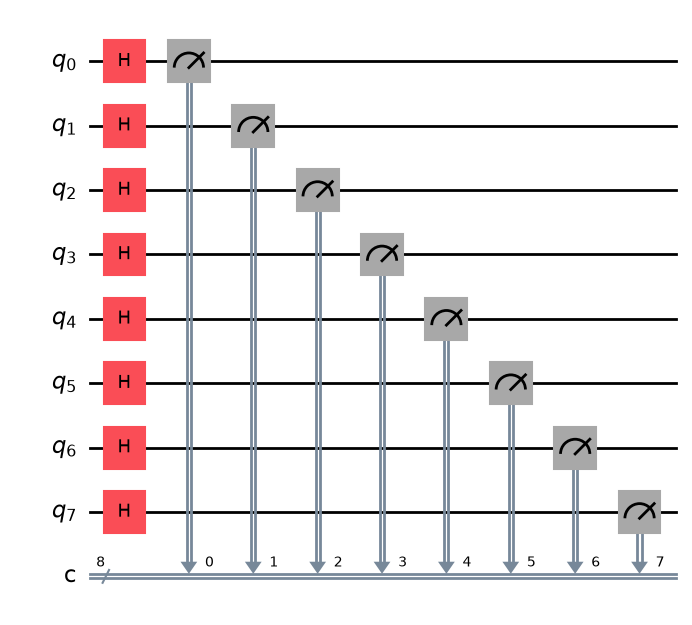

In [3]:
# Build the 8-qubit circuit with Qiskit.
# show the saved picture of the same circuit instead.
N_QUBITS = 8
try:
    from qiskit import QuantumCircuit

    qc = QuantumCircuit(N_QUBITS, N_QUBITS)
    qc.h(range(N_QUBITS))                          # Hadamard gate on every qubit
    qc.measure(range(N_QUBITS), range(N_QUBITS))   # measure qubit i into classical bit i
    display(qc.draw("mpl"))
except Exception as err:
    print("Qiskit drawing not available here, showing the saved circuit picture instead.")
    display(Image("circuit_diagram.png"))

## 2.2 Step 2: Optimize for hardware <a id="optimize"></a>

Real quantum computers only support a small set of basic gates, so Qiskit rewrites our circuit to fit the device. This is called *transpiling*. Our circuit is tiny, so there is very little to optimize.

In [4]:
# Optional: transpile the circuit for Qiskit's simulator and show how small it is.
try:
    from qiskit import transpile
    from qiskit_aer import AerSimulator

    backend = AerSimulator()
    isa_circuit = transpile(qc, backend)
    print("Gate counts after transpiling:", dict(isa_circuit.count_ops()))
    print("Circuit depth:", isa_circuit.depth())
except Exception as err:
    print("Skipping the optional transpile demo (Qiskit/Aer not available):", err)

Gate counts after transpiling: {'h': 8, 'measure': 8}
Circuit depth: 2


## 2.3 Step 3: Execute on hardware and simulator <a id="execute"></a>

We have three sources of 1,000 bits each (125 shots × 8 bits):

- **IBM hardware** (`ibm_marrakesh`): physical quantum measurements, collected earlier and saved in `data/`.
- **Noisy simulator:** a classical program with deliberate readout errors that we chose.
- **Python `random`:** a deterministic algorithm (Mersenne Twister), our classical baseline.

The cell below runs a few shots live on Qiskit's simulator, just to show the circuit working. A simulator is a classical program, so these bits are pseudo-random, not physically quantum.

In [5]:
# a few shots on Qiskit's simulator.
try:
    sim = AerSimulator()
    result = sim.run(isa_circuit, shots=5, memory=True).result()
    shots = result.get_memory()
    print("5 live simulator shots:", shots)
    print("As numbers (0-255):   ", [int(s, 2) for s in shots])
except Exception as err:
    print("Skipping the live demo (Qiskit/Aer not available):", err)

5 live simulator shots: ['00000110', '00011101', '11111010', '00111010', '11010110']
As numbers (0-255):    [6, 29, 250, 58, 214]


## 2.4 Step 4: Post-process and analyse the results <a id="post"></a>

We turn the bits into numbers (0 to 255), then ask three things: are the 1s and 0s balanced, do the numbers spread evenly, and do the statistical tests find anything unusual?

## Is each source balanced?
A fair source gives about 50% ones, but never exactly 50%, because chance wobbles. The grey band shows how far a fair source usually wobbles with 1,000 bits. The p-value is the chance of seeing a result this lopsided from a fair source; below 0.05 is unusual.

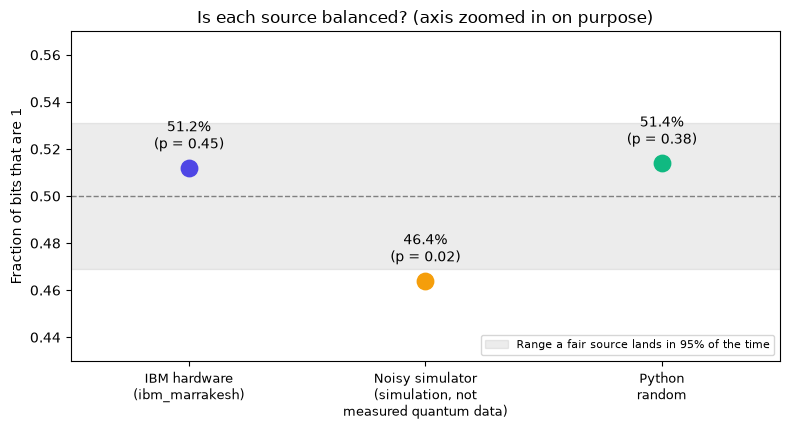

In [6]:
def ones_fraction(bits):
    return sum(bits) / len(bits)


def monobit_p_value(bits):
    """NIST-style frequency test: a small p-value means 0s and 1s are unbalanced."""
    n = len(bits)
    imbalance = abs(sum(2 * b - 1 for b in bits))
    return math.erfc(imbalance / math.sqrt(2 * n))


n = len(hardware)
band = 1.96 * math.sqrt(0.25 / n)  # 95% range for a fair source

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.axhspan(0.5 - band, 0.5 + band, color="grey", alpha=0.15,
           label="Range a fair source lands in 95% of the time")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)

for i, (name, bits) in enumerate(datasets.items()):
    f = ones_fraction(bits)
    ax.scatter(i, f, s=140, color=COLORS[i], zorder=3)
    ax.annotate(f"{f:.1%}\n(p = {monobit_p_value(bits):.2f})", (i, f),
                textcoords="offset points", xytext=(0, 14), ha="center")

ax.set_xticks(range(len(datasets)))
ax.set_xticklabels(list(datasets), fontsize=9)
ax.set_ylim(0.43, 0.57)
ax.set_ylabel("Fraction of bits that are 1")
ax.set_title("Is each source balanced? (axis zoomed in on purpose)")
ax.legend(loc="lower right", fontsize=8)
ax.set_xlim(-0.5, 2.5)
plt.tight_layout()
plt.show()


## Can you tell them apart by eye?
Below are the 125 numbers (0-255) from each source, grouped into 16 buckets. A perfect generator would put the same count in every bucket (dashed line). None of the three looks "more random" than the others.

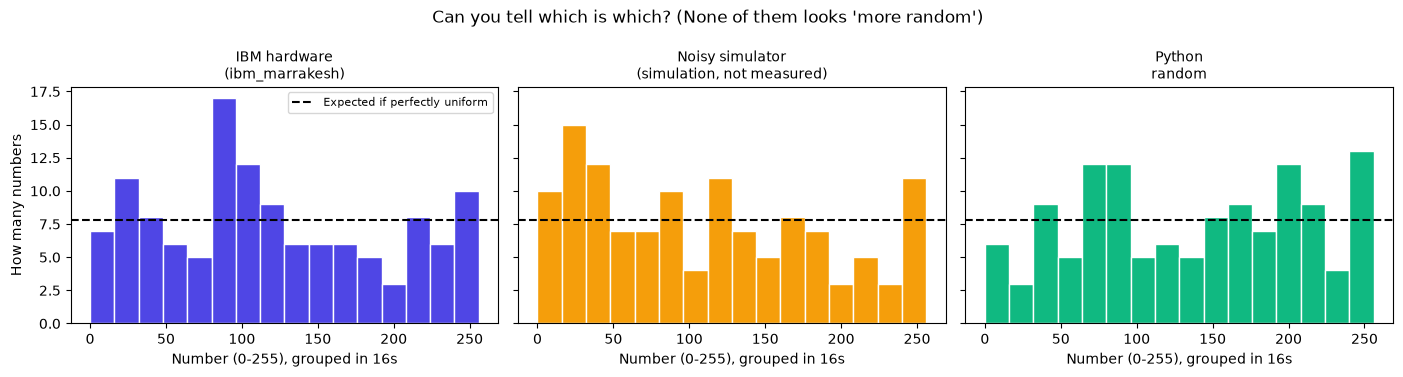

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)

for ax, color, (name, bits) in zip(axes, COLORS, datasets.items()):
    numbers = bits_to_numbers(bits)
    ax.hist(numbers, bins=range(0, 257, 16), color=color, edgecolor="white")
    ax.axhline(len(numbers) / 16, color="black", linestyle="--",
               label="Expected if perfectly uniform")
    title_label = name.replace("\n(simulation, not\nmeasured quantum data)", "\n(simulation, not measured)")
    ax.set_title(title_label, fontsize=10)
    ax.set_xlabel("Number (0-255), grouped in 16s")

axes[0].set_ylabel("How many numbers")
axes[0].legend(fontsize=8)
fig.suptitle("Can you tell which is which? (None of them looks 'more random')")
plt.tight_layout()
plt.show()


## Statistical tests

To test whether a sequence behaves like true random bits, statistical tests check for specific patterns or flaws. Passing these tests means **"no flaw was found"**, not that the sequence is **"proven random"** (since classical formulas can also pass them).

Here are the six key measures we evaluate (from Mike in `statistical_comparison.py`):
1. **Counts of 0s and 1s:** A balanced 50/50 source of 1,000 bits should produce approximately 500 zeros and 500 ones.
2. **Longest Run:** The length of the longest streak of identical consecutive bits (e.g. `111111...`). In truly random data of 1,000 bits, streaks should be relatively short (typically 9 to 11 bits). Extremely long streaks suggest sticking or correlation.
3. **Monobit Frequency Test ($p$-value):** Tests the overall balance of 0s vs 1s against a standard normal distribution. A $p$-value $\ge 0.05$ indicates balanced frequencies consistent with fair randomness; a $p$-value $< 0.05$ indicates a statistically significant imbalance.
4. **Runs Test:** Measures how often the bitstream alternates between 0 and 1 (transitions). Too few runs indicates clustering; too many runs indicates alternating oscillation.
5. **Shannon Entropy:** Measures information content per bit ($H = -\sum p_i \log_2 p_i$). A fair binary source has a theoretical maximum entropy of $1.0000$ bit/bit.
6. **Lag-1 Autocorrelation:** Checks whether bit $b_i$ predicts the next bit $b_{i+1}$. Values close to $0.0$ indicate successive bits are linearly independent.


### Statistical Test Results (1,000 bits per source)

| Source | 1s (0s) | Fraction 1s | Longest Run | Total Runs | Monobit p-value | Entropy (bits) | Lag-1 Autocorr |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| IBM hardware (ibm_marrakesh) | 512 (488) | 0.5120 | 10 | 507 | 0.447884 | 0.9996 | -0.0136 |
| Noisy simulator (simulation, not measured) | 464 (536) | 0.4640 | 11 | 490 | 0.022796 | 0.9963 | 0.0159 |
| Python random (baseline) | 514 (486) | 0.5140 | 11 | 494 | 0.375921 | 0.9994 | 0.0122 |


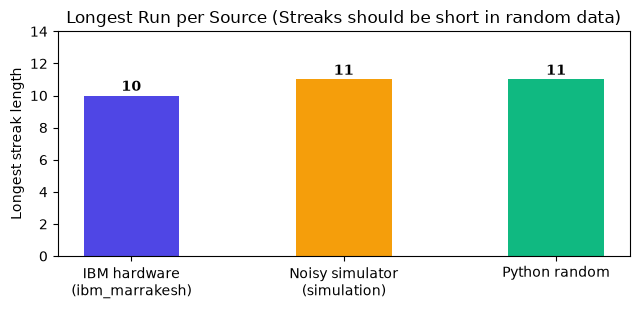

### Interpretation of Results
- **IBM Hardware (`ibm_marrakesh`, job `dbplvroqtr0c738elbe0`):** Measured **512 ones** (51.2%) with a monobit $p$-value of **0.447884** ($\ge 0.05$, balanced). Its longest streak of identical bits is **10**, with **507 total runs**, entropy of **0.9996**, and lag-1 autocorrelation of **-0.0136**.
- **Python Random (Mersenne Twister baseline):** Generated **514 ones** (51.4%) with a monobit $p$-value of **0.375921** and longest run of **11**. Like the hardware, it passes all tests in this 1,000-bit sample.
- **Noisy Simulator (Simulation, not measured data):** Produced **464 ones** (46.4%) with a monobit $p$-value of **0.022796** ($< 0.05$) and longest run of **11**. The deliberate readout error asymmetry produces a statistically significant imbalance towards 0, exactly as predicted.


In [8]:
# Import statistical comparison functions by Mike in statistical_comparison.py
from statistical_comparison import summarize_dataset

# Compute statistical summaries for all three sources
summary_hw = summarize_dataset(f"IBM hardware ({hw_source})", hardware)
summary_noisy = summarize_dataset("Noisy simulator (simulation, not measured)", noisy)
summary_py = summarize_dataset("Python random (baseline)", python_bits)

summaries = [summary_hw, summary_noisy, summary_py]

# 1. Display results table in clean Markdown
table_md = """### Statistical Test Results (1,000 bits per source)

| Source | 1s (0s) | Fraction 1s | Longest Run | Total Runs | Monobit p-value | Entropy (bits) | Lag-1 Autocorr |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
"""
for s in summaries:
    table_md += (
        f"| {s['label']} "
        f"| {s['ones']} ({s['zeros']}) "
        f"| {s['proportion_ones']:.4f} "
        f"| {s['longest_run']} "
        f"| {s['runs']['total_runs']} "
        f"| {s['monobit']['p_value']:.6f} "
        f"| {s['entropy']:.4f} "
        f"| {s['autocorrelation_lag_1']:.4f} |\n"
    )
display(Markdown(table_md))

# 2. Small bar chart of the longest run per source
fig, ax = plt.subplots(figsize=(6.5, 3.2))
source_short_names = [f"IBM hardware\n({hw_source})", "Noisy simulator\n(simulation)", "Python random"]
longest_runs = [s["longest_run"] for s in summaries]
bars = ax.bar(source_short_names, longest_runs, color=COLORS, width=0.45)
ax.set_ylabel("Longest streak length")
ax.set_title("Longest Run per Source (Streaks should be short in random data)")
ax.set_ylim(0, max(longest_runs) + 3)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 0.3, str(h), ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Short interpretation formatted dynamically from actual computed numbers
p_verdict = "$\\ge 0.05$, balanced" if summary_hw['monobit']['p_value'] >= 0.05 else "$< 0.05$, imbalanced"
interpretation_md = f"""### Interpretation of Results
- **IBM Hardware (`{hw_source}`, job `{hw_job_id}`):** Measured **{summary_hw['ones']} ones** ({summary_hw['proportion_ones']:.1%}) with a monobit $p$-value of **{summary_hw['monobit']['p_value']:.6f}** ({p_verdict}). Its longest streak of identical bits is **{summary_hw['longest_run']}**, with **{summary_hw['runs']['total_runs']} total runs**, entropy of **{summary_hw['entropy']:.4f}**, and lag-1 autocorrelation of **{summary_hw['autocorrelation_lag_1']:.4f}**.
- **Python Random (Mersenne Twister baseline):** Generated **{summary_py['ones']} ones** ({summary_py['proportion_ones']:.1%}) with a monobit $p$-value of **{summary_py['monobit']['p_value']:.6f}** and longest run of **{summary_py['longest_run']}**. Like the hardware, it passes all tests in this 1,000-bit sample.
- **Noisy Simulator (Simulation, not measured data):** Produced **{summary_noisy['ones']} ones** ({summary_noisy['proportion_ones']:.1%}) with a monobit $p$-value of **{summary_noisy['monobit']['p_value']:.6f}** ($< 0.05$) and longest run of **{summary_noisy['longest_run']}**. The deliberate readout error asymmetry produces a statistically significant imbalance towards 0, exactly as predicted.
"""
display(Markdown(interpretation_md))


## 2.5 Noise Detective <a id="noise"></a>
Our simulator is an offline classical simulation, not a physical quantum measurement. It models a deliberate, chosen flaw: a qubit holding 1 is sometimes misread as 0 (12% of the time, an assumption we chose), while 0 is misread as 1 less often (5%, also our choice; neither number was measured from a physical device, and no physical relaxation ($T_1$) decay was modelled). Because of this asymmetric readout error, we predicted a bias towards 0 before looking at the data.


In [9]:
# Parameters of OUR noise model (assumptions chosen by us, not measured from a real device; no T1 decay modelled).
P_READ_0_GIVEN_1 = 0.12   # a qubit that is 1 gets misread as 0
P_READ_1_GIVEN_0 = 0.05   # a qubit that is 0 gets misread as 1

expected_ones = 0.5 * (1 - P_READ_0_GIVEN_1) + 0.5 * P_READ_1_GIVEN_0
observed_ones = ones_fraction(noisy)

print(f"Predicted fraction of 1s from the noise model: {expected_ones:.1%}")
print(f"Observed in the noisy simulation:              {observed_ones:.1%}")
print("The bias is explained: 1s are misread as 0 more often than the reverse (simulation, not measured quantum data).")


Predicted fraction of 1s from the noise model: 46.5%
Observed in the noisy simulation:              46.4%
The bias is explained: 1s are misread as 0 more often than the reverse (simulation, not measured quantum data).


# 3. The three questions <a id="questions"></a>

**1. Can you tell the quantum results from Python's by looking?**
No. The charts and basic tests can't separate them. Python's generator is designed to look random, and 1,000 bits is too few to expose any pattern. The difference is where the randomness comes from, not how it looks.

**2. What tests could check the numbers look random?**
A frequency test (are 0s and 1s balanced?), a runs test (are streaks the right length?), entropy, and autocorrelation (does one bit predict the next?). Passing means "no flaw found", not "proven random".

**3. How "quantum" is a simulator's randomness?**
Barely. A simulator is a classical program using a classical pseudo-random generator, like Python. Only the hardware run gets its randomness from a physical measurement. Even then, real hardware has small biases.

# Conclusions <a id="conclusions"></a>
- Superposition plus measurement gives a bit that no formula can predict.
- With 1,000 bits, real hardware and Python both show statistically balanced bit frequencies; statistics cannot tell them apart.
- Our noisy simulator's bias matched what its readout errors predicted, so noise leaves a fingerprint (offline simulation with chosen parameters, not measured device data).
- A simulator is classical; only the hardware run has a physical quantum origin.

**Honest limits:** 1,000 bits is small, we have a single hardware run, our noise numbers were chosen assumptions rather than measured, and passing tests never proves true randomness ("no flaw found", not "proven random").
